<a href="https://colab.research.google.com/github/OJB-Quantum/MuMax3-How-To/blob/main/MuMax%20Notebooks/Standard_Problem_2_MuMaxPlus.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
! echo "This machine runs" $(uname) "with" $(python --version) "and provides the following GPU/CUDA specs:"
! nvidia-smi

In [ ]:
!uv pip install mumaxplus matplotlib numpy

100%|██████████| 30/30 [00:55<00:00,  1.83s/it]


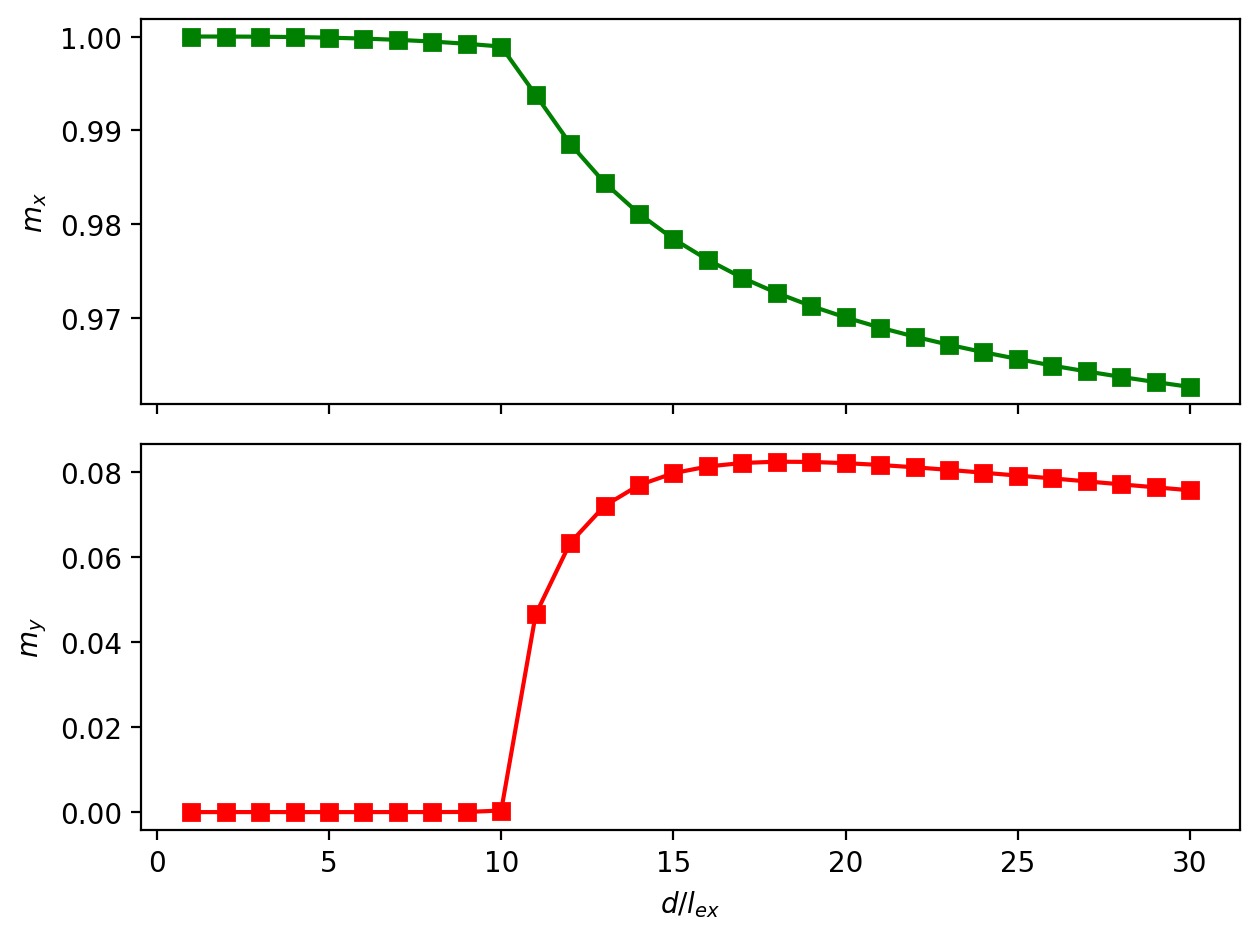

In [3]:
# This script solves micromagnetic standard problem 2. The Problem specification
# can be found on https://www.ctcms.nist.gov/~rdm/mumag.org.html
# The coercivity for small particles can also be compared to the analytical value
# https://pubs.aip.org/aip/jap/article-abstract/87/9/5520/530184/Behavior-of-MAG-standard-problem-No-2-in-the-small

import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm  # progress bar

from mumaxplus import Ferromagnet, Grid, World
from mumaxplus.util.constants import MU0

plt.rcParams['figure.dpi'] = 200

calculate_coercivity = False  # set to True for coercivity, but takes very long

# dimensions
d_min, d_max, d_step = 1, 30, 1  # dimensionless widths d = width/l_ex
# maybe lower d_max when calculating coercivity
d_array = np.arange(d_min, d_max + 0.5*d_step, d_step)
t_p_d = 0.1  # thickness/width ratio
L_p_d = 5.0  # length/width ratio

# taking realistic parameters, but does not matter
msat = 800e3
aex = 13e-12
l_ex = np.sqrt(2*aex / (MU0 * msat**2))

def get_next_power_of_2(x):
    y = 1
    while y < x:
        y *= 2
    return y

def get_gridsize(L, d, t):
    """Cell length should at least be < l_ex/2. The number of cells is best
    a power of 2 for FFT. This results in cell sizes between 0.25*l_ex and
    0.5*l_ex."""
    return (get_next_power_of_2(2*L), get_next_power_of_2(2*d), get_next_power_of_2(2*t))

mx_list, my_list = [], []
rHc_list = []
for d in tqdm(d_array):
    L = L_p_d * d  # dimensionless length L = length/l_ex
    t = t_p_d * d  # dimensionless thickness t = thickness/l_ex

    nx, ny, nz = get_gridsize(L, d, t)
    world = World(cellsize=(L*l_ex/nx, d*l_ex/ny, t*l_ex/nz))
    magnet = Ferromagnet(world, Grid((nx, ny, nz)))
    magnet.msat = msat
    magnet.aex = aex

    magnet.magnetization = (1, 1, 1)  # fully saturated in specified direction
    magnet.minimize()  # TODO: try relax

    m = magnet.magnetization.average()  # remnance magnetization
    mx_list.append(m[0])
    my_list.append(m[1])

    # Coercivity
    if calculate_coercivity:
        H_direction = np.asarray((-1,-1,-1))/np.sqrt(3)  # opposite direction
        rH_min = 0.0400
        rH_step = 0.0002  # lower is better H_C resolution

        rHmag = rH_min  # H field magnitude relative to Msat
        rHmag_prev = 0  # remnance was calculated without field

        # non-normalized magnetization along [1,1,1] direction
        m_prev = np.sum(magnet.magnetization.average())
        world.bias_magnetic_field = MU0 * rHmag * msat * H_direction  # B field in Tesla
        magnet.minimize()
        m_cur = np.sum(magnet.magnetization.average())
        # keep raising the magnetic field magnitude until the magnet flips
        while m_cur > 0:
            # save previous attempts
            rHmag_prev = rHmag
            m_prev = m_cur

            rHmag += rH_step  # raise field magnitude
            world.bias_magnetic_field = MU0 * rHmag * msat * H_direction
            magnet.minimize()

            m_cur = np.sum(magnet.magnetization.average())  # find m projection

        # linearly interpolate where mx+my+mz=0 => best relative coercive field H_C/Msat
        rHc = (m_prev*rHmag - m_cur*rHmag_prev) / (m_prev - m_cur)
        rHc_list.append(rHc)


# --- Plotting ---

# remnance magnetization
fig, axs = plt.subplots(nrows=2, sharex="all")
mx_ax, my_ax = axs
mx_ax.plot(d_array, mx_list, marker="s", c="g")
my_ax.plot(d_array, my_list, marker="s", c="r")
mx_ax.set_ylabel("$m_x$")
my_ax.set_ylabel("$m_y$")
my_ax.set_xlabel("$d/l_{ex}$")

# coercivity
if calculate_coercivity:
    fig, ax = plt.subplots()
    ax.plot(d_array, rHc_list, marker="s", label="simulated")
    ax.scatter(0, 0.057069478, marker="o", label="analytical", c="r")  # analytical
    ax.set_xlabel("$d/l_ex$")
    ax.set_ylabel(r"$H_C/M_{\rm sat}$")
    ax.legend()

plt.tight_layout()
plt.show()